# Workshop 2 — IIR DELAY EFFECT
 - **Student:** Francesc SERRA CRESPÍ
 - **Email:** francesc.serra-crespi@universite-paris-saclay.fr
 - **Master Program:** M2 AI

In [1]:
import scipy.io.wavfile as wav
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import copy
from numpy.fft import fft, fftfreq, ifft
from scipy.fft import fftshift
from scipy.signal import fftconvolve

# 1. Fundamental Elements

## 1.1 Signal representation

We developed a signal_data class to simplify the manipulation and analysis of audio signals. The class stores the main properties of the signal, including the sampling rate, number of samples, duration, time vector, Nyquist frequency, and frequency resolution.

For a discrete signal containing (N) samples and sampled at a frequency (f_s), the main quantities are defined as:

$$
\Delta t = \frac{1}{f_s}
\qquad
T = \frac{N}{f_s}
\qquad
f_{\max} = \frac{f_s}{2}
\qquad
\Delta f = \frac{f_s}{N}
$$

where ($Delta$) is the sampling interval, ($T$) is the signal duration, ($f_{\max}$) is the Nyquist frequency, and ($\Delta f$) is the frequency resolution.

In [2]:
class signal_data: # Class to store signal data
    def __init__(self, filename):
        self.filename = filename
        self.rate, self.data = wav.read(filename)
        self.increment = 1 / self.rate
        self.length = len(self.data)
        self.duration = self.length / self.rate
        self.time = np.arange(0, self.length) / self.rate
        self.freq_max = self.rate / 2
        self.resolution_freq = self.rate / self.length


## 1.2 Unit impulse

We also defined a discrete unit impulse signal. It is represented as an array of ($N$) samples in which the first sample is equal to 1 and all the remaining samples are equal to 0:

$$
\delta[n] =
\begin{cases}
1, & n=0\\

0, & n\neq0
\end{cases}
$$

The unit impulse is particularly important because it allows us to obtain the impulse response of a system $h[n]$ for the $FIR$ filter a linear time-invariant system.

In [3]:
class delta_signal: # Class to store delta signal data
    def __init__(self, length):
        self.length = length
        self.data = np.zeros(length)
        self.data[0] = 1

## 1.3 IIR Filter

The $IIR$ filter was implemented as a function that receives the input signal together with three parameters: the input gain $\alpha$, the feedback gain $\beta$, and the delay $D$.

Unlike the FIR filter, the IIR filter uses a delayed and scaled version of the **previous output** as feedback. Its equation is:

$$
y[n] = \alpha x[n] + \beta y[n-D]
$$

where $x[n]$ is the input signal, $y[n]$ is the filtered output, $D$ is the delay expressed in samples, $\alpha$ controls the contribution of the input signal, and $\beta$ controls the amplitude of the delayed feedback component.

Since the output depends on previous output samples, the system has a recursive structure and therefore an infinite impulse response. As will be discussed in the following sections, this feedback mechanism is also directly related to the stability of the system. Each delayed repetition is multiplied again by $\beta$, so its amplitude evolves proportionally to $\beta^k$. Therefore, when $|\beta|<1$, the successive repetitions decay and converge to zero, resulting in a stable system. In contrast, when $|\beta|>1$, their amplitude grows without bound, leading to an unstable system. The case $|\beta|=1$ represents the boundary condition, where the repetitions do not decay.


In [4]:
def IIR_filter(signal_data, alpha, beta, delay=1):
   
    filtred_signal = np.zeros(signal_data.length)
    for n in range(signal_data.length):
        if n < delay:
            filtred_signal[n] = alpha * signal_data.data[n]
        else:
            filtred_signal[n] = alpha * signal_data.data[n] + beta * filtred_signal[n - delay]

    return filtred_signal

# 2. Download of the audio and initial visulalization in time domain not in sampling doamin

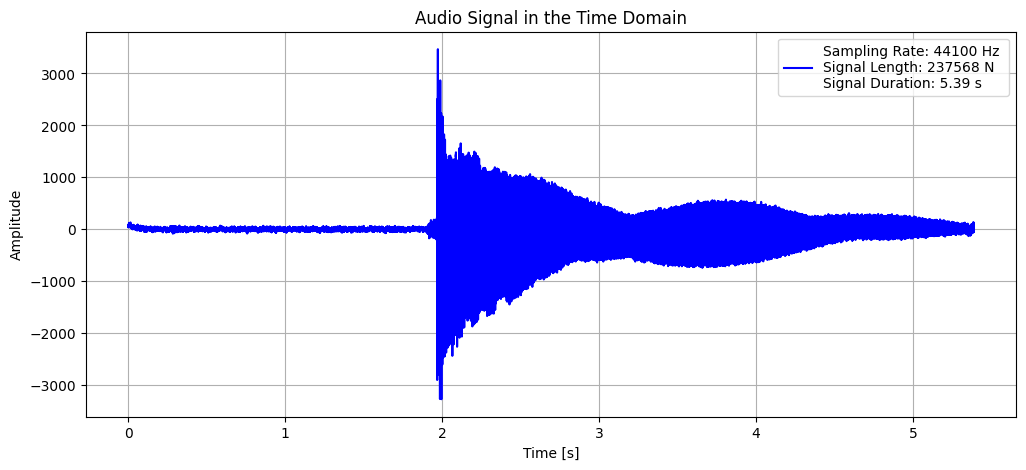

In [5]:
audio_signal = signal_data('data/string_1.wav')


plt.figure(figsize=(12, 5))
sns.lineplot(x=audio_signal.time, y=audio_signal.data,
    label=(
        f"Sampling Rate: {audio_signal.rate} Hz \n"
        f"Signal Length: {audio_signal.length} N\n"
        f"Signal Duration: {audio_signal.duration:.2f} s"),
    color='blue')

plt.title('Audio Signal in the Time Domain')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.grid()


# 3. IIR Filter Design and Signal Filtering

In [6]:
# IIR filter parameters
delay_samples = 20000  # Delay in samples
alpha_value = 1.5  # Feedback coefficient
beta_value = 0.8  # Feedforward coefficient

print(f"Applying IIR filter with delay of {delay_samples} samples ({delay_samples * audio_signal.increment:.2f} seconds) and alpha value of {alpha_value} and beta value of {beta_value}.")

Applying IIR filter with delay of 20000 samples (0.45 seconds) and alpha value of 1.5 and beta value of 0.8.


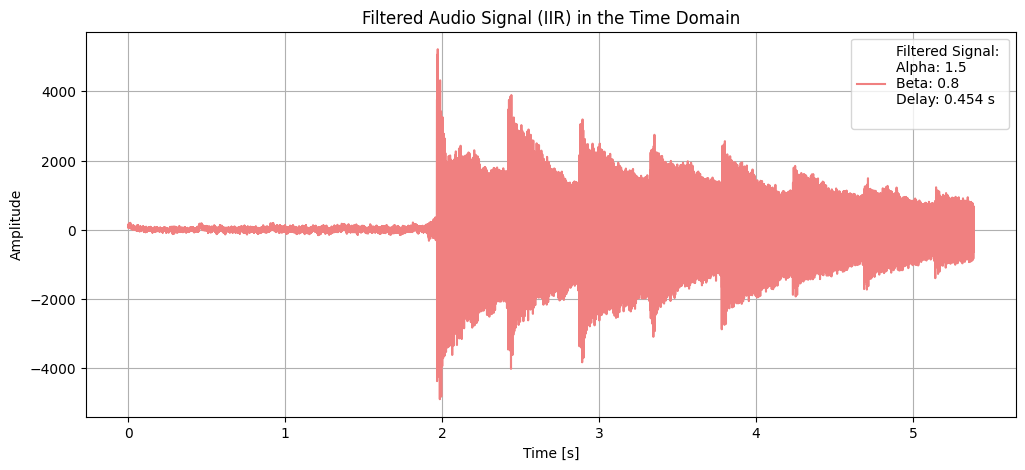

In [7]:

filtered_signal_data = IIR_filter(
    audio_signal,
    alpha=alpha_value,
    beta=beta_value,
    delay=delay_samples
)

seconds_delay= delay_samples * audio_signal.increment

# Plot 1 - Filtered signal
plt.figure(figsize=(12, 5))
sns.lineplot(
    x=audio_signal.time,
    y=filtered_signal_data,
    label=(
        'Filtered Signal: \n'
        f'Alpha: {alpha_value} \n'
        f'Beta: {beta_value} \n'
        f'Delay: {seconds_delay:.3f} s\n'),
    color='lightcoral'
)

plt.title('Filtered Audio Signal (IIR) in the Time Domain')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.grid()


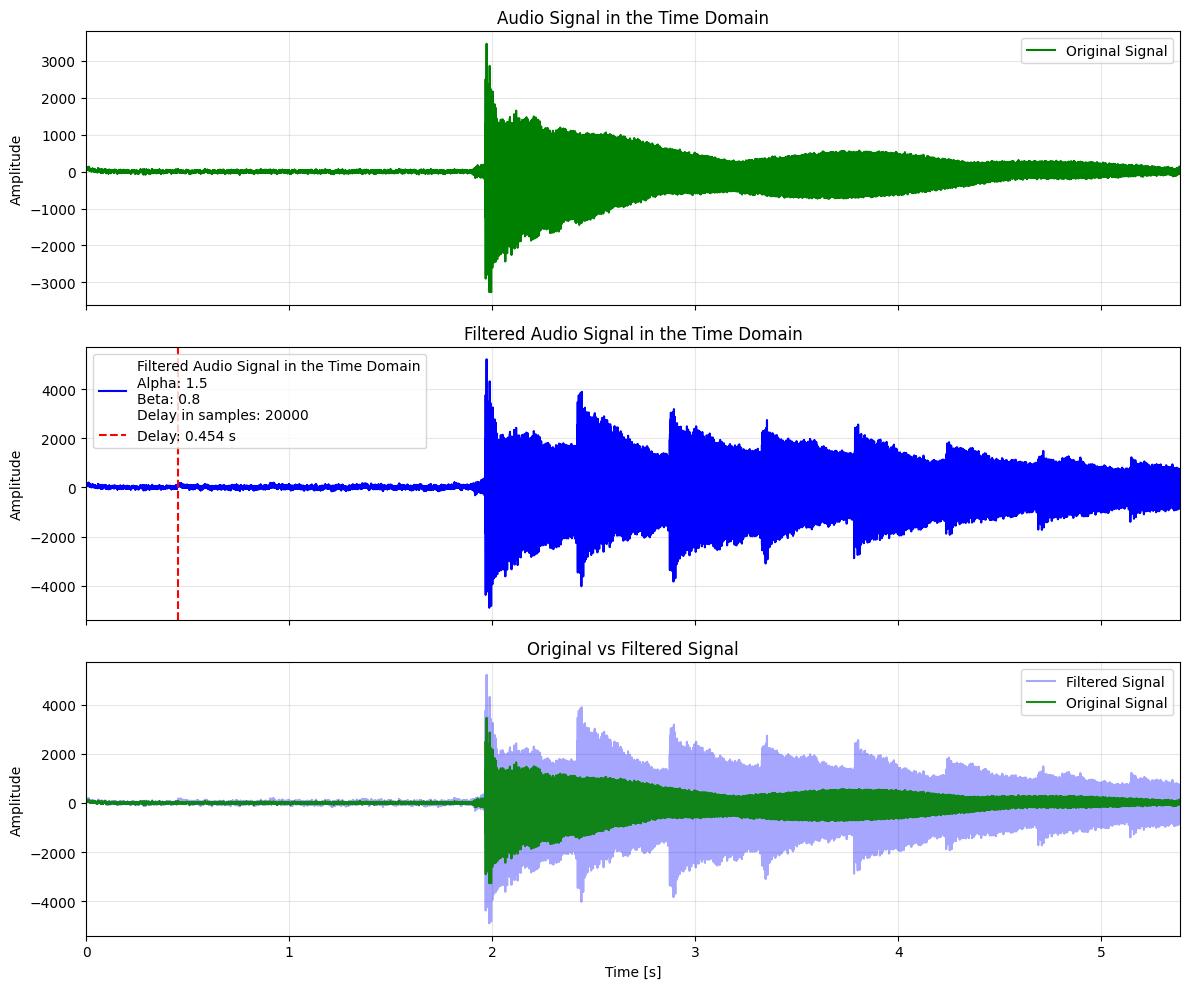

In [8]:
filtered_signal_data = IIR_filter(
    audio_signal,
    alpha=alpha_value,
    beta=beta_value,
    delay=delay_samples
)

seconds_delay= delay_samples * audio_signal.increment



fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Plot 0 - Original signal
sns.lineplot( x=audio_signal.time, y=audio_signal.data,
    ax=axes[0],
    label='Original Signal',
    color='green')


axes[0].set_title('Audio Signal in the Time Domain')
axes[0].set_ylabel('Amplitude')
axes[0].grid(alpha=0.3)
axes[0].legend()

# Plot 1 - Filtered signal
sns.lineplot(
    x=audio_signal.time,
    y=filtered_signal_data,
    ax=axes[1],
    label=(f'Filtered Audio Signal in the Time Domain\n'
           f'Alpha: {alpha_value} \n'
           f'Beta: {beta_value} \n'
           f'Delay in samples: {delay_samples}'),
    color='b')

axes[1].axvline(x=seconds_delay, color='r', linestyle='--', label=f'Delay: {seconds_delay:.3f} s')

axes[1].set_title('Filtered Audio Signal in the Time Domain')
axes[1].set_ylabel('Amplitude')
axes[1].grid(alpha=0.3)
axes[1].legend()


# Plot 2 - Original + filtered

sns.lineplot( x=audio_signal.time, y=filtered_signal_data,
    ax=axes[2],
    label='Filtered Signal',
    color='blue',
    alpha=0.35)

sns.lineplot( x=audio_signal.time, y=audio_signal.data,
    ax=axes[2],
    label='Original Signal',
    color='green',
    alpha=0.9)

axes[2].set_title(
    f'Original vs Filtered Signal'
)

axes[2].set_xlabel('Time [s]')
axes[2].set_ylabel('Amplitude')
axes[2].set_xlim(0, audio_signal.duration)
axes[2].grid(alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

## Insight
> The effect of the IIR filter is less straightforward to identify visually than in the FIR case because the output is generated recursively.
>
> During the first $D$ samples, the delayed feedback has not yet contributed to the output. Therefore, the signal is only affected by the direct input term:
>
> $$
> y[n]=\alpha x[n], \qquad 0\leq n<D
> $$
>
> Once the first delay is reached, the previous output starts contributing to the current signal. Since this contribution is fed back into the system, new delayed components are generated recursively every $D$ samples.
>
> Expanding the recursion gives:
>
> $$
> y[n]
> =
> \alpha x[n]
> +\alpha\beta x[n-D]
> +\alpha\beta^2x[n-2D]
> +\alpha\beta^3x[n-3D]
> +\cdots
> $$
>
> This shows that each successive contribution:
>
> - is delayed by an additional $D$ samples,
> - is scaled by a factor $\beta$ with respect to the previous contribution,
> - and has an overall amplitude proportional to $\alpha\beta^k$.
>
> The evolution of the output can therefore be understood progressively as:
>
> $$
> y[n]=
> \begin{cases}
> \alpha x[n], & 0\leq n<D\\[4pt]
> \alpha x[n]+\alpha\beta x[n-D], & D\leq n<2D\\[4pt]
> \alpha x[n]+\alpha\beta x[n-D]+\alpha\beta^2x[n-2D], & 2D\leq n<3D\\[4pt]
> \vdots
> \end{cases}
> $$
>
> When $|\beta|<1$, the factor $\beta^k$ decreases in magnitude as $k$ increases. Therefore, each successive delayed contribution becomes progressively smaller and the effect of the feedback decays over time.
>
> The final output is thus the superposition of several delayed and scaled contributions. Because multiple delayed components overlap, the effect of the IIR filter is less visually distinguishable than the single delayed copy produced by the FIR filter.

# 4. Impulse Response
The impulse response $h[n]$ represents the output of the filter when a discrete Dirac delta $\delta[n]$ is applied as the input signal.


## 4.1 Case Where $|\beta|<1$


Text(0, 0.5, 'Impulse Response h[n]')

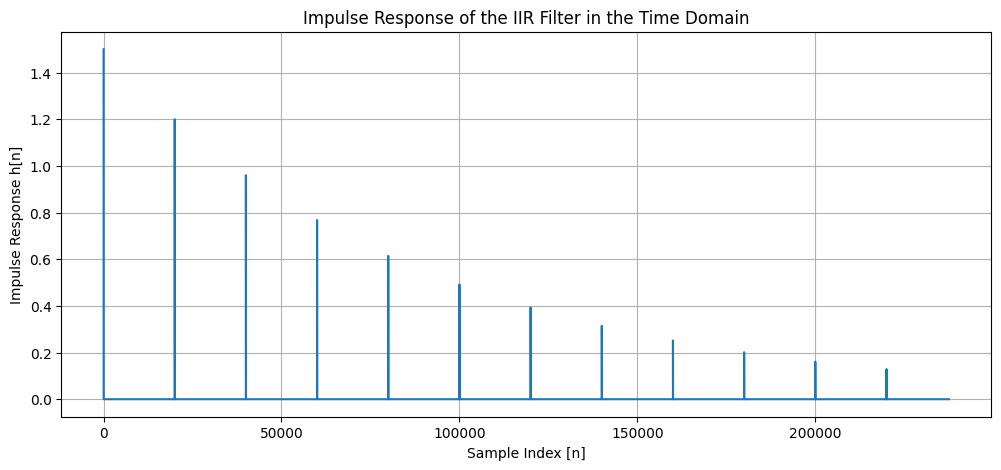

In [9]:
N = len(audio_signal.data)
delta = delta_signal(N)

impulse_response = IIR_filter(delta, alpha=alpha_value, beta=beta_value, delay=delay_samples)

plt.figure(figsize=(12, 5))
sns.lineplot(x=range(N), y=impulse_response)
plt.grid()
plt.title('Impulse Response of the IIR Filter in the Time Domain')
plt.xlabel('Sample Index [n]')
plt.ylabel('Impulse Response h[n]')

### Insight
> The stability of the IIR filter is directly determined by the value of $\beta$.
>
> If $|\beta|<1$, then:
>
> $$
> \beta^k \rightarrow 0 \qquad \text{as} \qquad k\rightarrow\infty
> $$
>
> Therefore, the amplitude of each successive recursive contribution,
>
> $$
> \alpha\beta^k,
> $$
>
> becomes progressively smaller. As a result, the feedback decays over time and the output eventually converges. In this case, the system is stable.

## 4.2 Case Where $|\beta|==1$

Text(0, 0.5, 'Impulse Response h[n]')

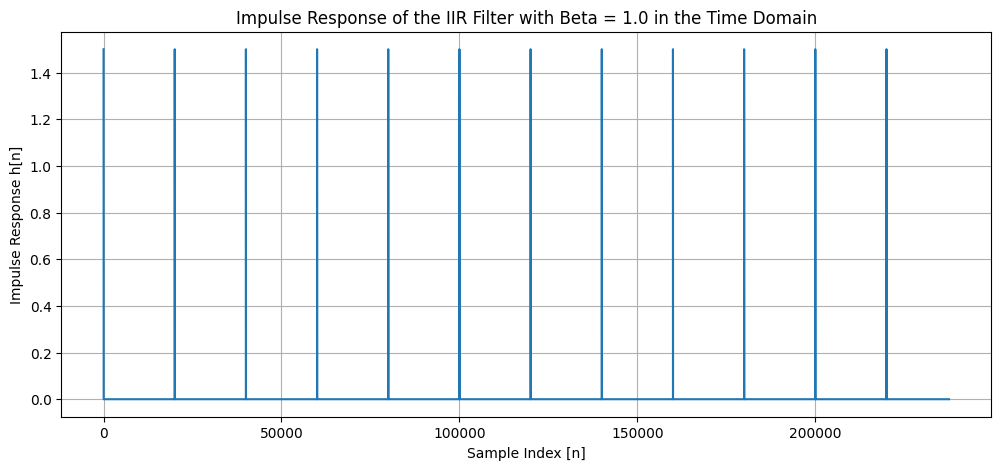

In [10]:
N = len(audio_signal.data)
delta = delta_signal(N)

impulse_response_limit = IIR_filter(delta, alpha=alpha_value, beta=1.0, delay=delay_samples)

plt.figure(figsize=(12, 5))
sns.lineplot(x=range(N), y=impulse_response_limit)
plt.grid()
plt.title('Impulse Response of the IIR Filter with Beta = 1.0 in the Time Domain')
plt.xlabel('Sample Index [n]')
plt.ylabel('Impulse Response h[n]')

### Insight

> The case $|\beta|=1$ represents the boundary between decaying and growing feedback.
>
> For $\beta=1$:
>
> $$
> \alpha\beta^k=\alpha
> $$
>
> for every value of $k$. Therefore, each recursive contribution keeps the same amplitude $\alpha$ instead of decreasing or increasing.
>
> The feedback does not grow without bound, but it also does not decay to zero. 

## 4.3 Case Where $|\beta|>1$

Text(0, 0.5, 'Impulse Response h[n]')

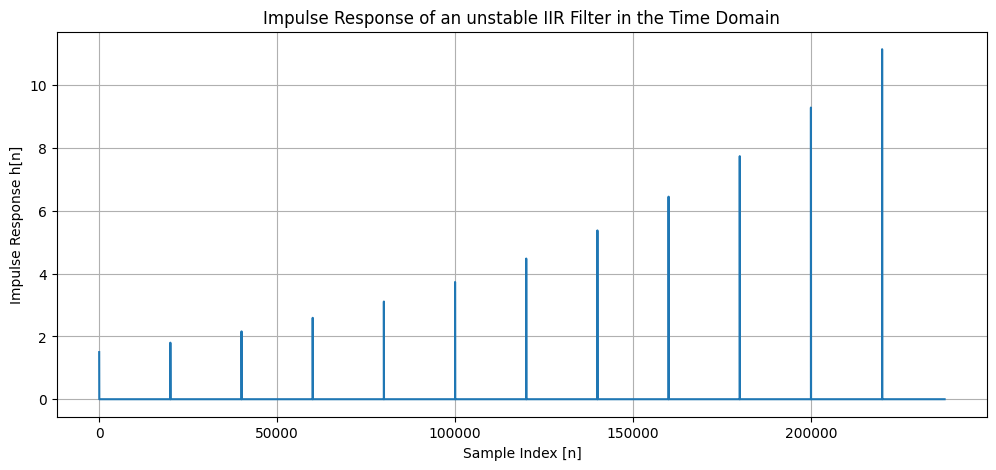

In [11]:
N = len(audio_signal.data)
delta = delta_signal(N)

impulse_response_inestable = IIR_filter(delta, alpha=alpha_value, beta=1.2, delay=delay_samples)

plt.figure(figsize=(12, 5))
sns.lineplot(x=range(N), y=impulse_response_inestable)
plt.grid()
plt.title('Impulse Response of an unstable IIR Filter in the Time Domain')
plt.xlabel('Sample Index [n]')
plt.ylabel('Impulse Response h[n]')

### Insight

> If $|\beta|>1$, then:
>
> $$
> |\beta|^k \rightarrow \infty
> \qquad \text{as} \qquad
> k\rightarrow\infty
> $$
>
> Therefore, the amplitude of the recursive contribution,
>
> $$
> \alpha\beta^k,
> $$
>
> becomes increasingly larger after every delay.
>
> As a result, the feedback grows without bound instead of decaying, causing the output amplitude to increase progressively. In this case, the system is unstable.

# 5. FIR Filter Analysis in the Frequency Domain

Once the impulse response $h[n]$ is obtained, its Fourier Transform gives us the **frequency response of the filter**, $H(f)$. This allows us to understand how the filter affects the different frequency components of the input signal.

Another important advantage of the frequency domain is that filtering can be performed using a simple element-wise multiplication, however in the time domain, the output is obtained through convolution.

Text(0, 0.5, 'Magnitude')

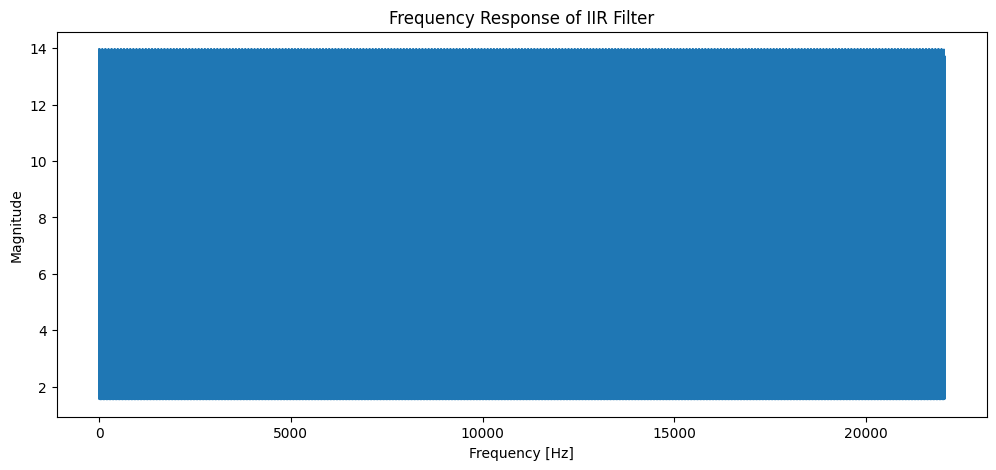

In [12]:
# frequency response of the filter

# 1. Discrete Fourier Transform (DFT)
fft_sig_s1 = fft(impulse_response)
freqs_s1 = fftfreq(len(impulse_response), d=1/audio_signal.rate)

# Centered version (zero in the middle), for a symmetric plot
sig_s1_shift = fftshift(fft_sig_s1)
f_s1_shift = fftshift(freqs_s1)
mag_shift = np.abs(sig_s1_shift)

# One-sided version: positive frequencies only
mitad = len(impulse_response) // 2
f_pos = freqs_s1[:mitad]
mag_pos = 2 * np.abs(fft_sig_s1[:mitad])

# Plot frequency response
plt.figure(figsize=(12, 5))
sns.lineplot(x=f_pos, y=mag_pos)
plt.title('Frequency Response of IIR Filter')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')


Text(0, 0.5, 'Magnitude')

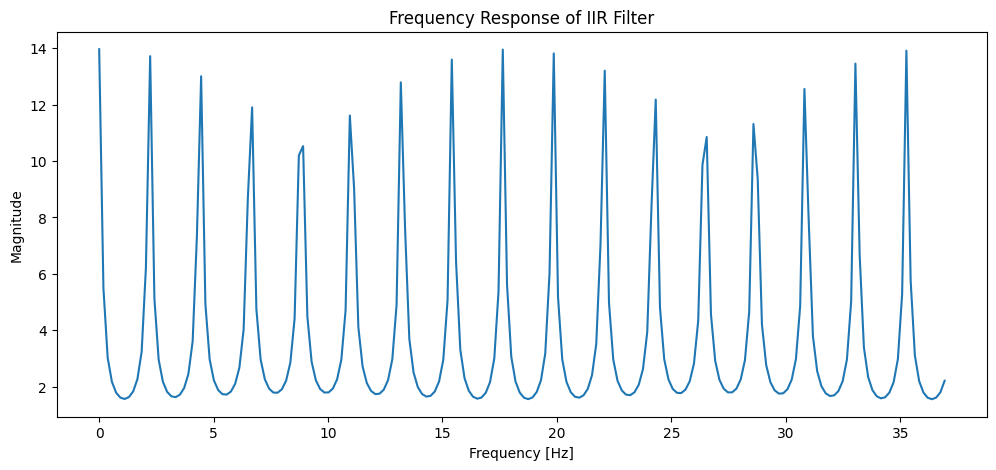

In [13]:
# Plot frequency response
plt.figure(figsize=(12, 5))
sns.lineplot(x=f_pos[0:200], y=mag_pos[0:200])
plt.title('Frequency Response of IIR Filter')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')

## Frequency Response Insight

> The frequency response has periodic characteristics similar to those observed in the FIR filter, rather than the typical shape of a low-pass, high-pass, band-pass, or band-stop filter.
>
> This frequency-domain representation will be useful in the next section, where we compare filtering in the time domain through convolution with filtering in the frequency domain through point-wise multiplication, taking into account the zero-padding required to obtain linear convolution.

# 6. Time-Domain Convolution vs. Frequency-Domain Pointwise Multiplication
As in the FIR case, the filtered signal can be obtained either by convolution in the time domain:

$$
y[n]=x[n]*h[n]
$$

or equivalently by point-wise multiplication in the frequency domain:
$$
Y(f)=X(f)\cdot H(f)
$$

To make both results equivalent, the signals must be zero-padded before applying the FFT, since FFT multiplication naturally produces circular convolution. For linear convolution, the required length is:

$$
L=L_1+L_2-1
$$

## 6.1 Time-Domain Convolution

Length of convolution result: 237568
Length of filtered signal: 237568


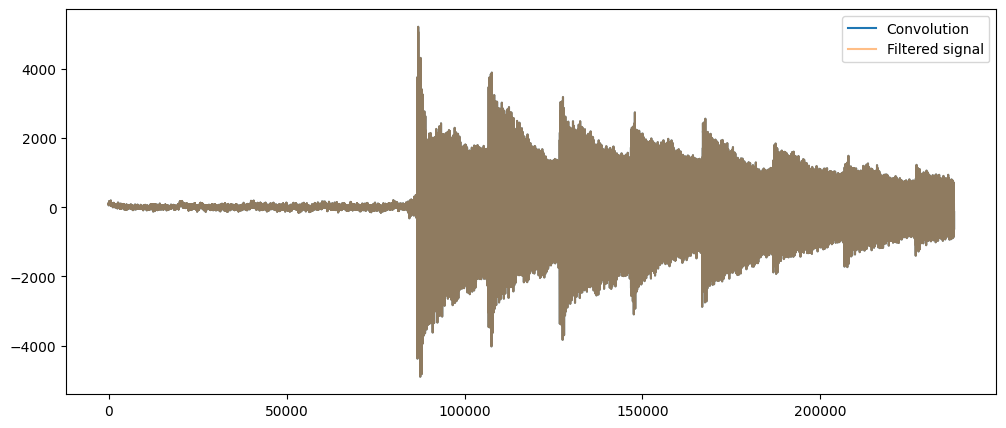

Is the filtered signal equal to the convolution signal? True


In [14]:
from scipy.signal import fftconvolve

# Full convolution
conv_full = fftconvolve(
    audio_signal.data,
    impulse_response,
    mode="full" # we have used full to be able to obtain a linear convolution with the requirement of Lx + Lh - 1
)

# Keep the causal part corresponding to the original signal
conv_signal = conv_full[:len(audio_signal.data)]

print(f'Length of convolution result: {len(conv_signal)}')
print(f'Length of filtered signal: {len(filtered_signal_data)}')

plt.figure(figsize=(12, 5))
plt.plot(conv_signal, label="Convolution")
plt.plot(filtered_signal_data, label="Filtered signal", alpha=0.5)
plt.legend()
plt.show()

print(f'Is the filtered signal equal to the convolution signal? {np.allclose(conv_signal, filtered_signal_data)}')

## 6.2 Frequency-Domain Pointwise Multiplication

Length of original signal: 237568
Length of impulse response: 237568
Length required for linear convolution: 475135
Length of padded signal: 475135
Length of padded impulse response: 475135


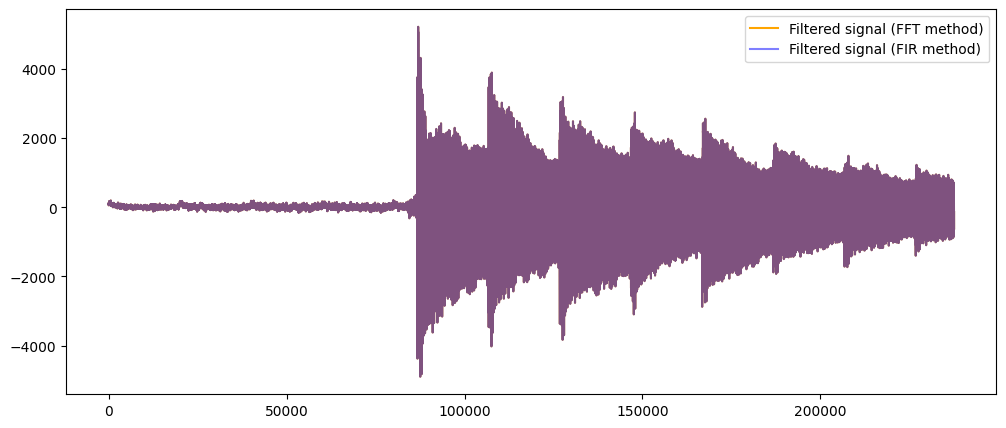

Is the filtered signal equal to the filtered signal using the FFT method? True


In [15]:



print(f"Length of original signal: {len(audio_signal.data)}")
print(f"Length of impulse response: {len(impulse_response)}")

N = 2 * audio_signal.length - 1
print(f"Length required for linear convolution: {N}")

# Amount of zero-padding needed
N_padding = N - len(audio_signal.data)

# Zero-padding
audio_signal_padded = np.pad(
    audio_signal.data,
    (0, N_padding),
    mode='constant'
)

impulse_response_padded = np.pad(
    impulse_response,
    (0, N_padding),
    mode='constant'
)

print(f"Length of padded signal: {len(audio_signal_padded)}")
print(f"Length of padded impulse response: {len(impulse_response_padded)}")

# FFT
audio_signal_fft = fft(audio_signal_padded)
impulse_response_fft = fft(impulse_response_padded)

# Multiplication in frequency domain
audio_signal_filtered_fft = (
    audio_signal_fft * impulse_response_fft
)

# Back to time domain
audio_signal_filtered_fftmethod = np.real(
    ifft(audio_signal_filtered_fft)
)[0:len(audio_signal.data)]  # Keep only the causal part corresponding to the original signal

# Compare
plt.figure(figsize=(12, 5))

plt.plot(
    audio_signal_filtered_fftmethod,
    label="Filtered signal (FFT method)",
    color='orange'
)

plt.plot(
    filtered_signal_data,
    label="Filtered signal (FIR method)",
    alpha=0.5,
    color='blue'
)

plt.legend()
plt.show()

print(f'Is the filtered signal equal to the filtered signal using the FFT method? {np.allclose(audio_signal_filtered_fftmethod, filtered_signal_data)}')

## Insight
> As in the tests performed for the FIR filter, the results obtained for the IIR filter are the same in the time and frequency domains.
>
> This equivalence comes from the convolution theorem:
>
> $$
> x[n]*h[n]
> \;\Longleftrightarrow\;
> X(f)\cdot H(f)
> $$
>
> Therefore, convolving the input signal with the IIR impulse response in the time domain is equivalent to multiplying their Fourier transforms point by point in the frequency domain.
>
> The plots and the sample-by-sample comparison confirm that both approaches produce the same result, apart from small numerical differences due to floating-point precision.
>
> As in the FIR case, zero-padding is required when using the FFT to obtain linear convolution and avoid circular convolution effects.

## 7. Conclusion: FIR vs IIR

The main difference between the FIR and IIR implementations is the presence of **feedback**.

The FIR filter does not use previous output values, so its impulse response has a finite duration and the system is **always stable regardless of its parameters**. In this case, the delay produces a single delayed and scaled copy of the original signal.

In contrast, the IIR filter uses the previous output through the feedback term:

$$
y[n]=\alpha x[n]+\beta y[n-D]
$$

Therefore, each delayed contribution generates another delayed contribution, producing a theoretically **infinite impulse response**:

$$
\alpha,\quad \alpha\beta,\quad \alpha\beta^2,\quad \alpha\beta^3,\ldots
$$

As a consequence, the stability of the IIR filter depends directly on the feedback gain $\beta$:

- If $|\beta|<1$, the successive contributions decrease and the system is stable.
- If $|\beta|>1$, the contributions increase and the output grows without bound, making the system unstable.
- If $|\beta|=1$, the contributions do not decay, corresponding to the stability boundary.

Thus, while the FIR filter produces a **single delayed repetition**, the IIR filter produces a sequence of progressively delayed repetitions whose amplitude is controlled by $\beta$. This feedback mechanism gives the IIR filter a longer and more complex response, but also makes its behavior strongly dependent on its parameters.